In [30]:
import numpy as np
import pandas as pd

from sklearn.metrics import root_mean_squared_error 
from tqdm import tqdm

import matplotlib.pyplot as plt

import os
os.chdir(r'E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')
import warnings
warnings.filterwarnings('ignore')

In [31]:
df

,Date,Daily total female births in California
0,01-01-1959,35
1,02-01-1959,32
2,03-01-1959,30
3,04-01-1959,31
4,05-01-1959,44
...,...,...
360,27-12-1959,37
361,28-12-1959,52
362,29-12-1959,48
363,30-12-1959,55


In [32]:
df = pd.read_csv("daily-total-female-births-in-cal.csv" )
y = df['Daily total female births in California']
y_train , y_test = y.iloc[:-31] , y.iloc[-31:]
y_train.shape , y_test.shape
# print(y)
# print("len : ",len(y))

((334,), (31,))

In [36]:
from statsmodels.tsa.api import Holt
from statsmodels.tsa.api import SimpleExpSmoothing

RMSE = 15.34


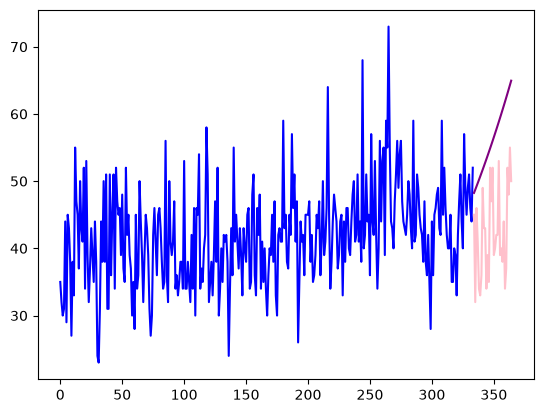

In [37]:
alpha ,beta = 0.1 , 0.2
holt = Holt(y_train , exponential=True)  # just changes equation but output looks same

fit1 = holt.fit(smoothing_level=alpha , smoothing_trend = beta)
fcast1 = fit1.forecast(len(y_test)) 
y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
print(f'RMSE = {rms}')

In [48]:
alpha , beta  = np.linspace(0.01,0.99,10) , np.linspace(0.01 , 0.99,10) 

scores = []

for a in tqdm(alpha):
    for b in beta: 

            holt = Holt(y_train , exponential=True) 
            
            fit1 = hw_add.fit(smoothing_level=a , smoothing_trend = b)  
            fcast1 = fit1.forecast(len(y_test)) 
               

            scores.append([a,b, root_mean_squared_error(y_test , fcast1)])

df_scores = pd.DataFrame(scores, columns = ['alpha' ,'beta','score'])
df_scores.sort_values('score')

100%|██████████| 10/10 [00:10<00:00,  1.06s/it]


,alpha,beta,score
4,0.010000,0.445556,6.295892
1,0.010000,0.118889,6.836434
27,0.227778,0.772222,7.496930
0,0.010000,0.010000,7.567709
2,0.010000,0.227778,7.961756
...,...,...,...
97,0.990000,0.772222,101.321753
88,0.881111,0.881111,102.568795
98,0.990000,0.881111,115.717850
89,0.881111,0.990000,117.602329


RMSE = 7.64


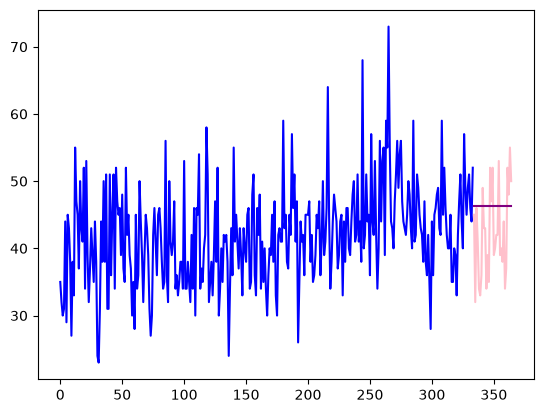

In [40]:
alpha = 0.112
ses = SimpleExpSmoothing(y_train)

fit1 = ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
print(f'RMSE = {rms}')


RMSE = 15.53


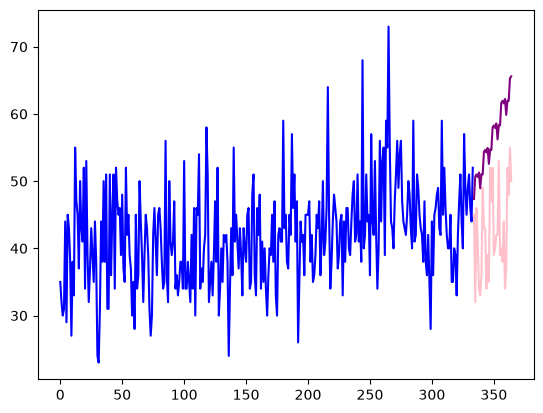

In [41]:
alpha ,beta, gamma = 0.1 , 0.2, 0.1
hw_add = ExponentialSmoothing(y_train , seasonal_periods=7 , trend = 'add' , seasonal='add')   

fit1 = hw_add.fit(smoothing_level= alpha , smoothing_trend = beta , smoothing_seasonal=gamma )
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
print(f'RMSE = {rms}')

In [29]:
from statsmodels.tsa.api import ExponentialSmoothing

In [42]:
alpha , beta , gamma = np.linspace(0.01,0.99,10) , np.linspace(0.01 , 0.99,10) , np.linspace(0.01 , 0.99,10)

scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
             
            hw_add = ExponentialSmoothing(y_train , seasonal_periods=7 , trend = 'add' , seasonal='add')   
            
            fit1 = hw_add.fit(smoothing_level=a , smoothing_trend=b, smoothing_seasonal=g)  
            fcast1 = fit1.forecast(len(y_test)) 
               

            scores.append([a,b,g, root_mean_squared_error(y_test , fcast1)])

df_scores = pd.DataFrame(scores, columns = ['alpha' ,'beta', 'gamma','score'])
df_scores.sort_values('score')

100%|██████████| 10/10 [00:57<00:00,  5.72s/it]


,alpha,beta,gamma,score
50,0.010000,0.554444,0.010000,6.157706e+00
41,0.010000,0.445556,0.118889,6.379191e+00
40,0.010000,0.445556,0.010000,6.662426e+00
32,0.010000,0.336667,0.227778,6.749323e+00
10,0.010000,0.118889,0.010000,6.824504e+00
...,...,...,...,...
979,0.990000,0.772222,0.990000,8.072559e+08
899,0.881111,0.990000,0.990000,4.989716e+09
998,0.990000,0.990000,0.881111,5.674444e+09
989,0.990000,0.881111,0.990000,1.459655e+10


RMSE = 6.16


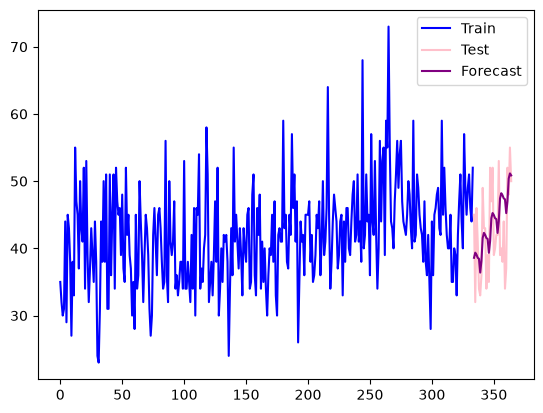

In [46]:
hw_add = ExponentialSmoothing(y_train , seasonal_periods=7 , trend = 'add' , seasonal='add')   
            
fit1 = hw_add.fit(smoothing_level=0.010000, smoothing_trend=0.554444, smoothing_seasonal=0.010000)  
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.legend(loc = 'best')
print(f'RMSE = {rms}')